<a href="https://colab.research.google.com/github/20deepak28/Customer-Lifetime-Value-Churn-Intelligence/blob/main/01_Data_collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Install Libraries

In [1]:
!pip install pandas numpy matplotlib seaborn
!pip install scikit-learn lightgbm shap
!pip install lifelines
!pip install causalml
!pip install psycopg2-binary
!pip install xgboost

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=9a0f81a035fb1d8b01fe5532857585a6c52e1be9e21c00472995fafa76caf133
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lifelines]
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 9.1 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 13.8 MB/s  0:00:00
  Created wheel for causalml: filename=causalml-0.18.0-cp313-cp313-linux_x86_64.whl size=9270512 sha256=d937048309ce9e51cc4288a39262058a073dcfe0e3cbb947b2a9a021e56cfdc2
  Stored in directory: /root/.cache/pip/wheels

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Environment ready!")

Environment ready!


### connecting drive with colab

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


setting the project directory

In [5]:
import os

project_path = '/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence'

os.makedirs(project_path, exist_ok=True)

os.chdir(project_path)

print("Current working directory:", os.getcwd())

Current working directory: /content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence


In [6]:
os.listdir(project_path)

[]

### Creating project's subfolders

In [7]:
folders = [
    'data',
    'notebooks',
    'models',
    'dashboard',
    'documentation'
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("All project folders created!")

All project folders created!


## Download the dataset

In [8]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset downloaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Saving the raw dataset in Google drive

In [9]:
data_path = os.path.join(project_path, 'data')

df.to_csv(os.path.join(data_path, 'telco_churn_raw.csv'), index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


### Initial Inspection

In [10]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include='all'))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


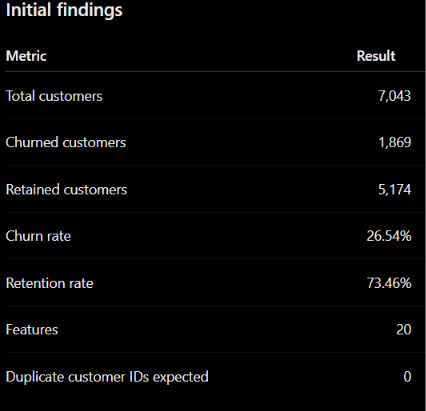

### Understading our target variables

In [11]:
print(df['Churn'].value_counts())

print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


# Data Quality Assessment

In [12]:
df_clean = df.copy()


### Investigate blank values

In [13]:
# Check empty strings and whitespace
for col in df_clean.columns:
    blanks = df_clean[col].astype(str).str.strip().eq('').sum()
    if blanks > 0:
        print(f"{col}: {blanks} blank values")

TotalCharges: 11 blank values


### Convert totalCharges into numeric

In [14]:
df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'].str.strip(),
    errors='coerce'
)

print(df_clean['TotalCharges'].isnull().sum())

11


### Investigate those 11 records

In [15]:
df_clean[df_clean['TotalCharges'].isnull()][
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


### Check duplicates

In [16]:
print("Duplicate rows:", df_clean.duplicated().sum())

print("Duplicate customer IDs:",
      df_clean['customerID'].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


#### Check numeric distributions

In [17]:
df_clean[['tenure', 'MonthlyCharges', 'TotalCharges']].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


### Investigating Missing Values

In [19]:
missing_records = df_clean[df_clean['TotalCharges'].isna()]

display(missing_records[
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
])

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


### Checking categorical Inconsistencies

In [20]:
categorical_columns = df_clean.select_dtypes(
    include='object'
).columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df_clean[col].value_counts())


customerID:
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup:
OnlineBackup
No                     3088
Yes                

### HAndeling Missing Values

In [21]:
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

These customers have just joined and have no accumulated charges yet. Zero is more appropriate than deleting their records or imputing an average.

In [22]:
print(df_clean.isnull().sum().sum())

print(df_clean['TotalCharges'].dtype)

0
float64


### feature Validation

In [23]:
print("Tenure range:",
      df_clean['tenure'].min(),
      df_clean['tenure'].max())

print("Monthly Charges range:",
      df_clean['MonthlyCharges'].min(),
      df_clean['MonthlyCharges'].max())

print("Total Charges range:",
      df_clean['TotalCharges'].min(),
      df_clean['TotalCharges'].max())

Tenure range: 0 72
Monthly Charges range: 18.25 118.75
Total Charges range: 0.0 8684.8


In [24]:
df_clean[
    df_clean['TotalCharges'] <
    df_clean['MonthlyCharges'] * df_clean['tenure'] * 0.95
].head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
10,9763-GRSKD,Male,0,Yes,Yes,13,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,49.95,587.45,No
21,1680-VDCWW,Male,0,Yes,No,12,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Bank transfer (automatic),19.80,202.25,No
25,6865-JZNKO,Female,0,No,No,30,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),55.30,1530.60,No
36,6047-YHPVI,Male,0,No,No,5,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.70,316.90,Yes
45,3714-NTNFO,Female,0,No,No,49,Yes,Yes,Fiber optic,No,...,No,No,No,Yes,Month-to-month,Yes,Electronic check,84.50,3906.70,No


### Save processed dataset

In [25]:
clean_path = os.path.join(
    data_path,
    'telco_churn_processed.csv'
)

df_clean.to_csv(clean_path, index=False)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


### Data Quality Assessment

- Total records: 7,043
- Total columns: 21
- Missing values: 0
- Duplicate rows: 0
- Duplicate Customer IDs: 0
- Corrected `TotalCharges` datatype to numeric.
- Handled 11 blank `TotalCharges` values by replacing them with 0, as these customers have zero tenure.

**Conclusion:** Dataset successfully cleaned and validated. Ready for Exploratory Data Analysis (EDA).